# AudX — khử nhiễu Anh–Việt cho ASR (CNN + LSTM)

**Mở rộng từ notebook gốc:** VoiceBank-DEMAND (cặp tiếng Anh) + VIVOS / FLEURS (tiếng Việt clean), FLEURS English + DEMAND / MUSAN / ESC-50 (mẫu noise thực), tùy chọn thư mục tiếng Việt tự thu. Tạo các cặp `(noisy.wav, clean.wav)` cùng độ dài/16kHz để train AudX, đánh giá riêng tiếng Việt và chuyển kết quả vào ASR.

- Các dataset và nguồn tải được liệt kê trong phần **Nguồn dữ liệu / Giấy phép** cuối notebook. Dữ liệu VIVOS, ESC-50, VietENT có hạn chế *non-commercial*; cần đối chiếu giấy phép theo ứng dụng.
- Chạy Colab hoặc Kaggle có GPU, internet và đủ dung lượng đĩa. **Không cần tải đủ 1 TB DNS Challenge**; tải mẫu giới hạn trước.
- Notebook chỉ **chuẩn bị và train khi thực sự chạy** trên runtime có internet/GPU. Không kèm theo checkpoint đã train.
- `MODE='demo'` dùng để smoke test; `MODE='full'` training thực tế, hãy kiểm soát số lượng augment.
- Phân chia: VoiceBank test giữ nguyên; FLEURS validation + ESC-50 fold 5 dùng đánh giá Việt **không đưa vào train**; DPDFNet EvalSet chỉ để benchmark.


## 1. Clone repo & cài thư viện

Nếu runtime đã chạy trước đó, cell dưới đây giữ lại repo hiện có. Mã train vẫn là kiến trúc `CNNLSTM` và hàm xử lý âm thanh trong repository, **không thay mô hình**.

In [1]:
import os, sys, subprocess
from pathlib import Path

# ROOT phải là đường dẫn tuyệt đối; sau os.chdir thì ROOT tương đối sẽ bị lồng AudX/AudX.
ROOT = Path('./AudX').resolve()
if not (ROOT / 'train.py').exists():
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/Mohitha-Gm/AudX.git', str(ROOT)], check=True)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print('Repository:', ROOT)


Cloning into '/kaggle/working/AudX'...


Repository: /kaggle/working/AudX


In [2]:
# Không cài lại torch (Colab/Kaggle có sẵn). datasets 3.6 tránh bắt buộc torchcodec của v4.
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'librosa>=0.10.2', 'soundfile', 'pystoi', 'huggingface_hub',
                'pyarrow', 'tqdm', 'matplotlib', 'datasets==3.6.0', 'jiwer'], check=True)
import torch
print('Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('Khuyến nghị bật GPU trong Colab/Kaggle')


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
pathos 0.3.5 requires dill>=0.4.1, but you have dill 0.3.8 which is incompatible.
pathos 0.3.5 requires multiprocess>=0.70.19, but you have multiprocess 0.70.16 which is incompatible.
s3fs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
tpot 1.1.0 requires dill>=0.3.9, but you have dill 0.3.8 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


Torch: 2.11.0+cu128 | CUDA: True
GPU: Tesla T4


## 2. Dataset tải từ đâu?

**Cách nhanh (mặc định):** [VoiceBank-DEMAND-16k trên Hugging Face](https://huggingface.co/datasets/JacobLinCool/VoiceBank-DEMAND-16k). Đã có audio 16 kHz và cặp `noisy`/`clean` (11.572 train, 824 test). Notebook tự tải **Parquet train/test** từ nguồn này. Ở chế độ demo, chỉ tải shard train đầu tiên (khoảng 444 MB) và file test (khoảng 132 MB), rồi xuất một số ít WAV.

**Nguồn gốc (lựa chọn thay thế):** [University of Edinburgh — VoiceBank + DEMAND](https://datashare.ed.ac.uk/items/6ed35425-bf14-4d2b-93a1-0a4984952757). Tải các file:

- `clean_trainset_28spk_wav.zip` (~2,32 GB)
- `noisy_trainset_28spk_wav.zip` (~2,64 GB)
- `clean_testset_wav.zip` (~147 MB)
- `noisy_testset_wav.zip` (~163 MB)

Dữ liệu Edinburgh gốc 48 kHz; mã bên dưới chuyển WAV đầu ra về 16 kHz. Với `DATA_SOURCE = "edinburgh_zip"`, **bạn cần tự tải bốn zip và đưa vào thư mục `ARCHIVE_DIR`** (ví dụ Drive). Không phải tải bộ 56 speakers hoặc tải riêng DEMAND. Tải dữ liệu ở máy trước rồi đặt trên Drive có thể tốn thời gian và dung lượng. Đọc điều kiện sử dụng tại nguồn.

## 3. Cấu hình

- `MODE="demo"`: 96 cặp train, 24 cặp test, 2 epoch; dùng để kiểm tra pipeline.
- `MODE="full"`: toàn bộ 11.572 train / 824 test và 30 epoch theo README (cần bộ nhớ/dung lượng và thời gian đáng kể).
- `DATA_SOURCE="hf"` tự động tải. Đổi thành `"edinburgh_zip"` nếu đã có các zip Edinburgh.
- Có thể bật lưu checkpoint vào Drive để không mất khi phiên Colab kết thúc.

In [3]:
DATA_SOURCE = 'hf'       # 'hf' hoặc 'edinburgh_zip'
MODE = 'full'           # 'demo' chạy thử; 'full' toàn bộ VoiceBank và nhiều cặp augment

N_TRAIN = 96 if MODE == 'demo' else None
N_TEST = 24 if MODE == 'demo' else None
EPOCHS = 2 if MODE == 'demo' else 30
BATCH_SIZE = 4 if MODE == 'demo' else 8
LEARNING_RATE = 1e-3

HF_REPO = 'JacobLinCool/VoiceBank-DEMAND-16k'
ARCHIVE_DIR = str(ROOT / 'voicebank_zips')
SAVE_TO_DRIVE = False
DRIVE_CKPT = './AudX_ckp/audx_model_finetuned_vi.pth'

DATA_DIR = ROOT / 'data' / 'VoiceBank'
CKPT = ROOT / 'audx_model_finetuned_vi.pth'  # path dùng nhất quán cho train/eval
for folder in ['noisy_trainset_28spk_wav', 'clean_trainset_28spk_wav',
               'noisy_testset_wav', 'clean_testset_wav']:
    (DATA_DIR / folder).mkdir(parents=True, exist_ok=True)

# if SAVE_TO_DRIVE:
#     from google.colab import drive
#     drive.mount('/content/drive')

assert DATA_SOURCE in ('hf', 'edinburgh_zip')
assert MODE in ('demo', 'full')
print('Source:', DATA_SOURCE, '| Mode:', MODE, '| Checkpoint:', CKPT)


Source: hf | Mode: full | Checkpoint: /kaggle/working/AudX/audx_model_finetuned_vi.pth


## 4. Chuẩn bị cặp audio `noisy` / `clean` và danh sách `train.txt`, `test.txt`

Cell sau tạo đúng cấu trúc mà `utils.dataset.VoiceBankDataset`, `train.py` và `evaluate_all.py` trong repo yêu cầu. Tên mỗi file được ghép theo ID của câu nói, không ghép theo thứ tự bất kỳ giữa noisy và clean.

**Lưu ý về dung lượng:** chế độ full trên Hugging Face tải khoảng 2,28 GB Parquet nén trước khi xuất WAV. Runtime Colab cần đủ dung lượng trống. Nếu chạy lại, WAV đã có sẽ không bị ghi lại.

In [4]:
import io, re, zipfile
import numpy as np
import soundfile as sf
import librosa
from tqdm.auto import tqdm

SPLITS = {
    'train': ('noisy_trainset_28spk_wav', 'clean_trainset_28spk_wav'),
    'test': ('noisy_testset_wav', 'clean_testset_wav'),
}

def save_audio_16k(audio, source_sr, target_path):
    audio = np.asarray(audio, dtype=np.float32)
    if audio.ndim == 2:
        audio = audio.mean(axis=1)
    if source_sr != 16000:
        audio = librosa.resample(audio, orig_sr=int(source_sr), target_sr=16000)
    sf.write(str(target_path), audio, 16000)


def write_pair(uid, noisy_audio, noisy_sr, clean_audio, clean_sr, split):
    # Không cho ID chứa đường dẫn / ký tự không mong đợi.
    uid = Path(str(uid)).stem
    if not re.fullmatch(r'[A-Za-z0-9_-]+', uid):
        raise ValueError(f'ID không hợp lệ: {uid}')
    noisy_folder, clean_folder = SPLITS[split]
    noisy_out = DATA_DIR / noisy_folder / (uid + '.wav')
    clean_out = DATA_DIR / clean_folder / (uid + '.wav')
    if not noisy_out.exists() or not clean_out.exists():
        save_audio_16k(noisy_audio, noisy_sr, noisy_out)
        save_audio_16k(clean_audio, clean_sr, clean_out)
    return uid


def wav_from_blob(audio_struct):
    # Hugging Face lưu Audio trong Parquet dưới dạng struct {bytes, path}.
    blob = audio_struct.get('bytes')
    if not blob:
        raise ValueError('Audio thiếu bytes trong Parquet; kiểm tra phiên bản dataset.')
    audio, sample_rate = sf.read(io.BytesIO(blob), dtype='float32')
    return audio, sample_rate


def export_from_hf(split, limit):
    from huggingface_hub import hf_hub_download
    import pyarrow.parquet as pq
    shards = ([f'data/train-{i:05d}-of-00005.parquet' for i in range(5)]
              if split == 'train' else ['data/test-00000-of-00001.parquet'])
    # Với demo, shard 0 là đủ 96 bản ghi; full lấy cả 5 shard train.
    if split == 'train' and limit is not None:
        shards = shards[:1]
    output_ids = []
    for name in shards:
        if limit is not None and len(output_ids) >= limit:
            break
        print('Đang lấy shard:', name)
        parquet_file = hf_hub_download(repo_id=HF_REPO, repo_type='dataset', filename=name)
        pq_file = pq.ParquetFile(parquet_file)
        for batch in tqdm(pq_file.iter_batches(batch_size=32, columns=['id', 'noisy', 'clean']),
                          desc=f'{split}: đọc Parquet', leave=False):
            for item in batch.to_pylist():
                uid = str(item['id'])
                noisy_folder, clean_folder = SPLITS[split]
                noisy_out = DATA_DIR / noisy_folder / (Path(uid).stem + '.wav')
                clean_out = DATA_DIR / clean_folder / (Path(uid).stem + '.wav')
                if not noisy_out.exists() or not clean_out.exists():
                    noisy, sr_noisy = wav_from_blob(item['noisy'])
                    clean, sr_clean = wav_from_blob(item['clean'])
                    write_pair(uid, noisy, sr_noisy, clean, sr_clean, split)
                output_ids.append(Path(uid).stem)
                if limit is not None and len(output_ids) >= limit:
                    return output_ids
    return output_ids


def export_from_edinburgh(split, limit):
    archive_path = Path(ARCHIVE_DIR)
    noisy_folder, clean_folder = SPLITS[split]
    noisy_zip_path = archive_path / f'{noisy_folder}.zip'
    clean_zip_path = archive_path / f'{clean_folder}.zip'
    for path in (noisy_zip_path, clean_zip_path):
        if not path.is_file():
            raise FileNotFoundError(f'Chưa có zip Edinburgh: {path}')
    with zipfile.ZipFile(noisy_zip_path) as nz, zipfile.ZipFile(clean_zip_path) as cz:
        noise_map = {Path(m.filename).stem: m for m in nz.infolist() if m.filename.lower().endswith('.wav')}
        clean_map = {Path(m.filename).stem: m for m in cz.infolist() if m.filename.lower().endswith('.wav')}
        ids = sorted(noise_map.keys() & clean_map.keys())
        if limit is not None:
            ids = ids[:limit]
        for uid in tqdm(ids, desc=f'{split}: chuyển WAV về 16 kHz'):
            noisy_out = DATA_DIR / noisy_folder / (uid + '.wav')
            clean_out = DATA_DIR / clean_folder / (uid + '.wav')
            if noisy_out.exists() and clean_out.exists():
                continue
            noisy, sr_noisy = sf.read(io.BytesIO(nz.read(noise_map[uid])), dtype='float32')
            clean, sr_clean = sf.read(io.BytesIO(cz.read(clean_map[uid])), dtype='float32')
            write_pair(uid, noisy, sr_noisy, clean, sr_clean, split)
        return ids


def prepare_split(split, limit):
    ids = (export_from_hf(split, limit) if DATA_SOURCE == 'hf'
           else export_from_edinburgh(split, limit))
    assert ids, f'Không tìm được cặp WAV nào cho {split}'
    list_file = DATA_DIR / f'{split}.txt'
    list_file.write_text(''.join(uid + '\n' for uid in ids), encoding='utf-8')
    noisy_folder, clean_folder = SPLITS[split]
    missing = [uid for uid in ids if not (DATA_DIR / noisy_folder / (uid + '.wav')).is_file()
               or not (DATA_DIR / clean_folder / (uid + '.wav')).is_file()]
    assert not missing, f'{split}: thiếu cặp audio: {missing[:5]}'
    print(f'{split}: {len(ids)} cặp | list: {list_file}')
    return ids

train_ids = prepare_split('train', N_TRAIN)
test_ids = prepare_split('test', N_TEST)
print('\nSẵn sàng:', DATA_DIR)

Đang lấy shard: data/train-00000-of-00005.parquet


data/train-00000-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  444MB            

data/train-00000-of-00005.parquet: downloading bytes:           |  0.00B            

train: đọc Parquet: 0it [00:00, ?it/s]

Đang lấy shard: data/train-00001-of-00005.parquet


data/train-00001-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  416MB            

... (15 outputs left out)

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  132MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

test: đọc Parquet: 0it [00:00, ?it/s]

test: 824 cặp | list: /kaggle/working/AudX/data/VoiceBank/test.txt

Sẵn sàng: /kaggle/working/AudX/data/VoiceBank


## 4B. Nguồn mở rộng Anh–Việt và bộ sinh noise

**Nguồn clean:** `duymanh1606/vietnamese_asr` (mirror Parquet VIVOS tiếng Việt, train-only; original [AILAB](https://huggingface.co/datasets/AILAB-VNUHCM/vivos) dùng loading script cũ), `google/fleurs` (`vi_vn` và `en_us`, **chỉ split train để huấn luyện**).

**Nguồn noise:** `corypaik/musan` (ambient + music + speech), `philgzl/demand` (16k, multichannel converted), `ashraq/esc50` (50 loại sự kiện môi trường, dùng fold 1–4 cho train), tùy chọn file noise ở Việt Nam trong các thư mục của bạn. `speech` từ MUSAN là người nói cạnh bên (*babble/interfering speech*) chứ không được coi là ground-truth của tiếng Việt.

Pipeline: clean mono 16 kHz → chọn 1 đến 3 nguồn noise độc lập → random crop, loop/crossfade → chuẩn hóa RMS và trộn SNR ngẫu nhiên `[-5, 20] dB` → **áp dụng cùng gain chống clipping lên noisy và clean** → lưu WAV đôi 16 kHz và ghi metadata. Có một tỷ lệ 5% `identity` (không nhiễu), giúp model không làm hỏng tiếng nói sạch.

Các cặp tổng hợp sẽ **được append vào `data/VoiceBank/train.txt`**, không đụng vào cặp test VoiceBank. Muốn thu nhiều noise ở Việt Nam, thêm thư mục `LOCAL_NOISE_DIRS` có thể chia thành `traffic/`, `market/`, `construction/`, `motorbike/`, `cafe/`, `fans/`, `rain/`, `street_vendor/`, `phone/`...

**Giới hạn:** corpus ASR chỉ là *approximately clean*, cần lọc thủ công mẫu bị rè/sẵn nhạc; dữ liệu tổng hợp không thay thế đánh giá bằng recording thực tế. SNR trước khi ghi WAV có sai số lượng tử PCM16 rất nhỏ.

In [5]:
%%writefile audx_data_augment.py
"""AudX Vietnamese/English clean-noisy data augmentation for 16 kHz VoiceBankDataset.

Usage in Colab/Kaggle: copy/embed this module into the AudX repository, then:
  from audx_data_augment import stage_hf, build_augmented_pairs, import_vietent_pairs, download_dpdfnet_vietnamese_eval

Only train.txt is appended; the original VoiceBank test.txt is left unchanged.
"""
from __future__ import annotations

import csv
import hashlib
import io
import math
import re
from pathlib import Path
from typing import Optional

import numpy as np
import soundfile as sf

SR = 16000
AUDIO_EXT = {'.wav', '.flac', '.ogg', '.mp3', '.opus', '.m4a'}


def resample_mono(x, source_sr: int):
    x = np.asarray(x, dtype=np.float32)
    if x.ndim == 2:
        # librosa/soundfile shapes: [samples, channels]; torchcodec: [channels, samples]
        if x.shape[0] <= 8 and x.shape[1] > x.shape[0]:
            x = x.mean(axis=0)
        else:
            x = x.mean(axis=1)
    if x.ndim != 1 or len(x) == 0:
        raise ValueError('Audio phải là một waveform không rỗng')
    if not np.all(np.isfinite(x)):
        raise ValueError('Audio có NaN/Inf')
    if int(source_sr) != SR:
        import librosa
        x = librosa.resample(x, orig_sr=int(source_sr), target_sr=SR)
    return np.clip(x.astype(np.float32), -1.0, 1.0)


def load_audio_file(path):
    path = Path(path)
    try:
        audio, sr = sf.read(str(path), dtype='float32', always_2d=False)
    except Exception:
        import librosa
        audio, sr = librosa.load(str(path), sr=None, mono=True)
    return resample_mono(audio, sr)


def hf_audio_to_array(audio):
    """Handle HF datasets <=3.x dictionary, dict(bytes), and torchcodec AudioDecoder."""
    if isinstance(audio, dict):
        if audio.get('array') is not None:
            return resample_mono(audio['array'], audio['sampling_rate'])
        if audio.get('bytes') is not None:
            blob = audio['bytes']
            try:
                wave, sr = sf.read(io.BytesIO(blob), dtype='float32')
            except Exception:
                # Some HF mirrors encode MP3/Opus, which soundfile may not open.
                import tempfile
                import librosa
                suffix = Path(audio.get('path') or 'sample.mp3').suffix or '.mp3'
                with tempfile.NamedTemporaryFile(suffix=suffix) as tmp:
                    tmp.write(blob)
                    tmp.flush()
                    wave, sr = librosa.load(tmp.name, sr=None, mono=True)
            return resample_mono(wave, sr)
        if audio.get('path') and Path(audio['path']).is_file():
            return load_audio_file(audio['path'])
    if hasattr(audio, 'get_all_samples'):
        samples = audio.get_all_samples()
        data = samples.data
        if hasattr(data, 'cpu'):
            data = data.cpu().numpy()
        return resample_mono(data, samples.sample_rate)
    raise TypeError(f'Không giải mã được audio HF: {type(audio)}')


def save_wav(dst, x):
    dst = Path(dst)
    dst.parent.mkdir(parents=True, exist_ok=True)
    sf.write(str(dst), np.asarray(x, dtype=np.float32), SR, subtype='PCM_16')


def slug(text):
    return re.sub(r'[^A-Za-z0-9_-]+', '_', str(text)).strip('_')[:85]


def stage_hf(repo, output, limit, *, config=None, split='train', label=None,
             select_fold=None, max_scan=None):
    """Download only selected HF audio records as local 16 kHz WAVs.

    For VIVOS use parquet mirror duymanh1606/vietnamese_asr.
    For DEMAND use split='16k'. For MUSAN use config='noise'|'music'|'speech'.
    If ESC-50 select_fold is set, keep folds in the chosen list.
    """
    from datasets import load_dataset
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    ds = load_dataset(repo, config, split=split, streaming=True)
    # Bốc mẫu giữa các shard/speaker thay vì lấy toàn bộ từ speaker đầu tiên.
    if hasattr(ds, 'shuffle'):
        ds = ds.shuffle(seed=2026, buffer_size=max(128, min(600, int(limit) * 2)))
    written = 0
    scanned = 0
    skipped = 0
    meta_path = output / '_stage_manifest.csv'
    rows = []
    for row in ds:
        scanned += 1
        if max_scan is not None and scanned > max_scan:
            break
        if select_fold is not None and row.get('fold') not in select_fold:
            continue
        ident = str(row.get('path') or row.get('name') or row.get('filename') or
                    row.get('id') or scanned)
        filename = f'{slug(label or repo.split("/")[-1])}_{written:06d}_{hashlib.md5(ident.encode()).hexdigest()[:8]}.wav'
        target = output / filename
        try:
            if not target.exists():
                audio = hf_audio_to_array(row['audio'])
                if len(audio) < SR // 4 or float(np.max(np.abs(audio))) < 1e-5:
                    skipped += 1
                    continue
                save_wav(target, audio)
            rows.append((filename, repo, str(config or ''), split, ident,
                         str(row.get('category') or ''), str(row.get('fold') or ''),
                         str(row.get('sentence') or row.get('transcription') or row.get('text') or '')))
            written += 1
        except Exception as e:
            skipped += 1
            if skipped <= 3:
                print('Bỏ qua HF audio lỗi:', ident, repr(e))
        if written >= int(limit):
            break
    with meta_path.open('w', newline='', encoding='utf8') as f:
        w = csv.writer(f)
        w.writerow(['wav', 'repo', 'config', 'split', 'original_id', 'category', 'fold', 'transcript'])
        w.writerows(rows)
    print(f'HF {repo}/{config or ""}/{split}: lưu {written}, bỏ qua {skipped} → {output}')
    if written == 0:
        raise RuntimeError(f'Không lấy được audio từ {repo} (kiểm tra quyền/truy cập và cột audio)')
    return written


def list_wavs(roots):
    files = []
    for root in roots:
        root = Path(root)
        if root.is_file() and root.suffix.lower() in AUDIO_EXT:
            files.append(root)
        elif root.is_dir():
            files.extend(p for p in root.rglob('*') if p.suffix.lower() in AUDIO_EXT)
    return sorted(set(files))


def _random_bed(noise, length, rng):
    """Random noise crop, or gently repeated noise for short clips."""
    noise = np.asarray(noise, dtype=np.float32)
    if len(noise) >= length:
        start = int(rng.integers(0, len(noise) - length + 1))
        return noise[start:start + length].copy()
    # Repeating short clips introduces small discontinuities: crossfade 15 ms.
    if len(noise) < 2:
        return np.zeros(length, dtype=np.float32)
    overlap = min(240, len(noise) // 4)
    if overlap < 1:
        return np.resize(noise, length).astype(np.float32)
    result = noise.copy()
    while len(result) < length:
        fade = np.linspace(0.0, 1.0, overlap, dtype=np.float32)
        seam = result[-overlap:] * (1.0 - fade) + noise[:overlap] * fade
        result = np.concatenate([result[:-overlap], seam, noise[overlap:]])
    return result[:length]


def rms(x):
    return float(np.sqrt(np.mean(np.square(np.asarray(x, dtype=np.float64))) + 1e-12))


def mix_snr(clean, noise_layers, snr_db):
    """Exact RMS-domain mixture SNR before common anti-clipping gain.

    clean and noisy receive the SAME gain, so the supervised target stays aligned.
    """
    clean = np.asarray(clean, dtype=np.float32)
    noise = np.sum(noise_layers, axis=0).astype(np.float32)
    if rms(noise) < 1e-5 or rms(clean) < 1e-5:
        raise ValueError('Clean/noise quá nhỏ để tính SNR')
    noise = noise * (rms(clean) / (10 ** (float(snr_db) / 20) * rms(noise)))
    noisy = clean + noise
    scale = min(1.0, 0.98 / max(float(np.max(np.abs(noisy))), float(np.max(np.abs(clean))), 1e-7))
    return (clean * scale).astype(np.float32), (noisy * scale).astype(np.float32)


def stable_seed(name, variant, seed):
    raw = f'{seed}/{name}/{variant}'.encode()
    return int.from_bytes(hashlib.sha256(raw).digest()[:8], 'little')


def build_augmented_pairs(*, data_dir, clean_roots, noise_roots, n_variants=2,
                          snr_low=-5., snr_high=20., seed=2026,
                          clean_fraction=0.05, multi_noise_fraction=0.35,
                          max_clean=None, max_seconds=30., prefix='aug',
                          source_lang='vi', max_noise_sources=3):
    """Add generated pairs to VoiceBank folders and train.txt (not test.txt).

    Reproducible; running twice doesn't duplicate train IDs. Roots can contain
    Vietnamese local noise, DNS, MUSAN, DEMAND, ESC-50, WHAM, speech-babble, etc.
    """
    data_dir = Path(data_dir)
    clean_files = list_wavs(clean_roots)
    noise_files = list_wavs(noise_roots)
    if not clean_files:
        raise ValueError('Không có clean WAV; kiểm tra clean_roots')
    if not noise_files:
        raise ValueError('Không có noise WAV; kiểm tra noise_roots')
    if max_clean is not None:
        clean_files = clean_files[:int(max_clean)]
    noisy_dest = data_dir / 'noisy_trainset_28spk_wav'
    clean_dest = data_dir / 'clean_trainset_28spk_wav'
    noisy_dest.mkdir(parents=True, exist_ok=True)
    clean_dest.mkdir(parents=True, exist_ok=True)
    train_txt = data_dir / 'train.txt'
    if not train_txt.is_file():
        raise FileNotFoundError('Cần chạy chuẩn bị VoiceBank trước để tạo train.txt')
    current = [line.strip() for line in train_txt.read_text(encoding='utf8').splitlines() if line.strip()]
    original_set = set(current)
    manifest_path = data_dir / 'augmented_manifest.csv'
    existing = set()
    if manifest_path.is_file():
        with manifest_path.open(encoding='utf8', newline='') as f:
            existing = {row['id'] for row in csv.DictReader(f)}
    newly_added, rows = [], []
    for src in clean_files:
        try:
            clean = load_audio_file(src)
            if len(clean) < int(0.4 * SR) or rms(clean) < 1e-4:
                continue
            # Preserve reasonable utterance length so CNN-LSTM can batch efficiently.
            if max_seconds and len(clean) > int(max_seconds * SR):
                clean = clean[:int(max_seconds * SR)]
            source_id = hashlib.sha1(str(src.resolve()).encode()).hexdigest()[:12]
            for variant in range(int(n_variants)):
                uid = f'{slug(prefix)}_{slug(source_lang)}_{source_id}_{variant:02d}'
                if (uid in original_set and (clean_dest/f'{uid}.wav').exists()
                    and (noisy_dest/f'{uid}.wav').exists()):
                    continue
                rng = np.random.default_rng(stable_seed(source_id, variant, seed))
                if rng.random() < clean_fraction:
                    target, noisy = clean.copy(), clean.copy()
                    snr = 'clean'
                    used = []
                else:
                    count = (int(rng.integers(2, max_noise_sources + 1))
                             if rng.random() < multi_noise_fraction else 1)
                    choices = rng.choice(len(noise_files), size=min(count, len(noise_files)),
                                         replace=False)
                    layers, used = [], []
                    for idx in choices:
                        npath = noise_files[int(idx)]
                        try:
                            layer = _random_bed(load_audio_file(npath), len(clean), rng)
                            if rms(layer) > 1e-5:
                                layers.append(layer)
                                used.append(str(npath))
                        except Exception:
                            continue
                    if not layers:
                        continue
                    snr = float(rng.uniform(snr_low, snr_high))
                    target, noisy = mix_snr(clean, layers, snr)
                # Atomic enough: never put ID into train until BOTH files are written.
                save_wav(clean_dest / f'{uid}.wav', target)
                save_wav(noisy_dest / f'{uid}.wav', noisy)
                newly_added.append(uid)
                if uid not in existing:
                    rows.append({'id': uid, 'language': source_lang, 'source_clean': str(src),
                                 'noise_paths': '|'.join(used), 'snr_db': snr,
                                 'variants': variant, 'sample_rate': SR})
        except Exception as e:
            print('Lỗi clean', str(src), repr(e))
            continue
    if newly_added:
        with train_txt.open('a', encoding='utf8') as f:
            for uid in newly_added:
                if uid not in original_set:
                    f.write(uid + '\n')
                    original_set.add(uid)
    fields = ['id', 'language', 'source_clean', 'noise_paths', 'snr_db', 'variants', 'sample_rate']
    if rows:
        write_header = not manifest_path.exists()
        with manifest_path.open('a', newline='', encoding='utf8') as f:
            writer = csv.DictWriter(f, fieldnames=fields)
            if write_header:
                writer.writeheader()
            writer.writerows(rows)
    print(f'Tạo mới {len(newly_added)} cặp ({source_lang}); tổng train.txt: {len(original_set)} cặp')
    return newly_added


def import_vietent_pairs(data_dir, *, limit=1000, split='train',
                         allow_unverified_alignment=False):
    """Optional: use *actual* raw/aug pairs from VietENT-Speech (synthetic TTS voices).

    Match by exact id, different `cond`, within a single official split. Data use
    is noncommercial, voice-clone consent issues: see dataset card.
    """
    if not allow_unverified_alignment:
        raise RuntimeError(
            'VietENT aug có thể đổi tốc độ nói, không bảo đảm paired framewise; '
            'không được import vào AudX MSE trước khi thực hiện kiểm tra/realign waveform.')
    from datasets import load_dataset
    data_dir = Path(data_dir)
    train_txt = data_dir / 'train.txt'
    if not train_txt.exists():
        raise FileNotFoundError(train_txt)
    ds = load_dataset('diepduclai/VietENT-Speech', split=split, streaming=True)
    buf = {}
    ids = set(train_txt.read_text().split())
    added = []
    for row in ds:
        cond = row.get('cond')
        if cond not in ('raw', 'aug'):
            continue
        key = str(row['id'])
        # Same ID + both conditions is a valid pair; NEVER pair only by text.
        item = buf.setdefault(key, {})
        item[cond] = row['audio']
        if 'raw' in item and 'aug' in item:
            uid = f'ent_{hashlib.sha1(key.encode()).hexdigest()[:16]}'
            if uid not in ids:
                raw = hf_audio_to_array(item['raw'])
                aug = hf_audio_to_array(item['aug'])
                if len(raw) == len(aug):
                    save_wav(data_dir/'clean_trainset_28spk_wav'/f'{uid}.wav', raw)
                    save_wav(data_dir/'noisy_trainset_28spk_wav'/f'{uid}.wav', aug)
                    added.append(uid)
                    ids.add(uid)
                else:
                    # Rate-change augmentation is not sample-aligned; do NOT
                    # time-warp or truncate and claim a valid denoising pair.
                    print('Bỏ VietENT không aligned:', key, len(raw), len(aug))
            del buf[key]
            if len(added) >= limit:
                break
    if added:
        with train_txt.open('a', encoding='utf8') as f:
            f.write(''.join(uid+'\n' for uid in added))
    print(f'VietENT: bổ sung {len(added)} cặp aligned. Lưu ý `aug` có thể đổi tốc độ nói.')
    return added


def download_dpdfnet_vietnamese_eval(output_dir, *, max_pairs=27):
    """Download only Vietnamese Clean/Noisy from DPDFNet **for evaluation**.

    NEVER append these pairs to VoiceBank train.txt. HF repo ~28 GB overall;
    selecting just two WAV directories with vietnamese prefix avoids that.
    """
    from huggingface_hub import list_repo_files, hf_hub_download
    repo = 'Ceva-IP/DPDFNet_EvalSet'
    output_dir = Path(output_dir)
    clean_dir = output_dir / 'clean'
    noisy_dir = output_dir / 'noisy'
    clean_dir.mkdir(parents=True, exist_ok=True)
    noisy_dir.mkdir(parents=True, exist_ok=True)
    files = list_repo_files(repo, repo_type='dataset')
    clean_map = {Path(f).name.replace('_mixture_clean.wav', ''): f for f in files
                 if f.startswith('Clean/') and f.endswith('_mixture_clean.wav')
                 and 'vietnamese' in Path(f).name.lower()}
    noisy_map = {Path(f).name.replace('_mixture_noisy.wav', ''): f for f in files
                 if f.startswith('Noisy/') and f.endswith('_mixture_noisy.wav')
                 and 'vietnamese' in Path(f).name.lower()}
    common = sorted(clean_map.keys() & noisy_map.keys())[:max_pairs]
    if not common:
        raise RuntimeError('Không có cặp vietnamese với tên như kỳ vọng; kiểm tra HF repo tree')
    pairs = []
    for key in common:
        for src, target_dir in [(clean_map[key], clean_dir), (noisy_map[key], noisy_dir)]:
            dst = target_dir / (key + '.wav')
            if not dst.exists():
                cached = hf_hub_download(repo, src, repo_type='dataset')
                save_wav(dst, load_audio_file(cached))
        pairs.append((key, clean_dir/(key+'.wav'), noisy_dir/(key+'.wav')))
    print(f'Vietnamese DPDFNet EVAL ONLY: {len(pairs)} pairs → {output_dir}')
    return pairs


def evaluate_pairs(pairs, enhance_fn, compute_fn, max_seconds=30):
    """Evaluate STOI/SDR/SI-SDR with bounded chunks to avoid LSTM OOM."""
    summary = {'noisy': [], 'enhanced': []}
    for _, clean_path, noisy_path in pairs:
        clean = load_audio_file(clean_path)
        noisy = load_audio_file(noisy_path)
        length = min(len(clean), len(noisy))
        span = int(SR * max_seconds)
        for start in range(0, length, span):
            c = clean[start:start+span]
            n = noisy[start:start+span]
            if len(c) < SR or rms(c) < 1e-4:
                continue
            enhanced = enhance_fn(n)
            L = min(len(c), len(n), len(enhanced))
            if L < SR:
                continue
            summary['noisy'].append(compute_fn(c[:L], n[:L]))
            summary['enhanced'].append(compute_fn(c[:L], enhanced[:L]))
    return summary


def build_synthetic_eval(*, clean_root, noise_root, output_dir, max_clean=100,
                         seed=83261, snr_low=-5., snr_high=15.):
    """Create a held-out Vietnamese noisy set with transcripts when available.

    Use FLEURS validation/test (not train) and ESC50 fold 5 (not folds 1-4).
    This output is NOT linked into AudX train/test.txt.
    """
    clean_root = Path(clean_root)
    output_dir = Path(output_dir)
    files = list_wavs([clean_root])[:int(max_clean)]
    noises = list_wavs([noise_root])
    if not files or not noises:
        raise ValueError('Cần clean eval và noise hold-out khác dữ liệu train')
    text_map = {}
    manifest_file = clean_root / '_stage_manifest.csv'
    if manifest_file.exists():
        with manifest_file.open(encoding='utf8', newline='') as f:
            text_map = {row['wav']: row.get('transcript', '') for row in csv.DictReader(f)}
    rows = []
    for i, src in enumerate(files):
        clean = load_audio_file(src)
        rng = np.random.default_rng(stable_seed(src.name, 0, seed))
        noise_src = noises[int(rng.integers(0, len(noises)))]
        bed = _random_bed(load_audio_file(noise_src), len(clean), rng)
        snr = float(rng.uniform(snr_low, snr_high))
        c, n = mix_snr(clean, [bed], snr)
        uid = f'vi_eval_{i:05d}'
        save_wav(output_dir / 'clean' / f'{uid}.wav', c)
        save_wav(output_dir / 'noisy' / f'{uid}.wav', n)
        rows.append({'id': uid, 'clean': str((output_dir/'clean'/f'{uid}.wav').resolve()),
                     'noisy': str((output_dir/'noisy'/f'{uid}.wav').resolve()),
                     'transcript': text_map.get(src.name, ''), 'snr_db': snr,
                     'noise_path': str(noise_src)})
    output_dir.mkdir(parents=True, exist_ok=True)
    with (output_dir/'eval_manifest.csv').open('w', encoding='utf8', newline='') as f:
        w = csv.DictWriter(f, fieldnames=['id','clean','noisy','transcript','snr_db','noise_path'])
        w.writeheader()
        w.writerows(rows)
    print('Đã tạo eval tiếng Việt với noise holdout:', len(rows))
    return [(row['id'], Path(row['clean']), Path(row['noisy'])) for row in rows]


Writing audx_data_augment.py


### 4B.1. Cấu hình và tải một phần dataset

`ENABLE_AUGMENTATION=True` và `AUTO_FETCH_HF=True` sẽ lấy các mẫu với giới hạn ở từng nguồn — không kéo toàn bộ kho âm thanh. Có thể tắt và chỉ dùng các thư mục local đã chuẩn bị. Các thư mục HF được cache ở `ROOT/extra_sources/` để không cần tải lại trên cùng runtime.

In [6]:
from audx_data_augment import (stage_hf, build_augmented_pairs,
                               build_synthetic_eval, evaluate_pairs,
                               download_dpdfnet_vietnamese_eval, import_vietent_pairs, load_audio_file)

ENABLE_AUGMENTATION = True
AUTO_FETCH_HF = True
# Nếu chạy offline: AUTO_FETCH_HF=False và đặt các thư mục clean/noise local bên dưới.
LOCAL_CLEAN_VI_DIRS = []  # ví dụ ['/kaggle/input/vietnamese-clean/wav']
LOCAL_CLEAN_EN_DIRS = []  # tùy chọn
LOCAL_NOISE_DIRS = []     # ví dụ ['/kaggle/input/vietnam-noises']
EXTRA_ROOT = ROOT / 'extra_sources'
EXTRA_ROOT.mkdir(parents=True, exist_ok=True)

LIMIT = {
 'vivos': 96 if MODE == 'demo' else 2000,
 'fleurs_vi': 48 if MODE == 'demo' else 1200,
 'fleurs_en': 24 if MODE == 'demo' else 400,
 'musan_noise': 45 if MODE == 'demo' else 250,
 'musan_music': 10 if MODE == 'demo' else 70,
 'musan_speech': 12 if MODE == 'demo' else 80,
 'demand': 60 if MODE == 'demo' else 350,
 'esc50_train': 50 if MODE == 'demo' else 250,
 'esc50_holdout': 30 if MODE == 'demo' else 100,
 'eval_vi_clean': 20 if MODE == 'demo' else 120,
}

HF_STAGE_SOURCES = [
    ('vivos', 'duymanh1606/vietnamese_asr', None, 'train', None),
    ('fleurs_vi', 'google/fleurs', 'vi_vn', 'train', None),
    ('fleurs_en', 'google/fleurs', 'en_us', 'train', None),
    ('musan_noise', 'corypaik/musan', 'noise', 'train', None),
    ('musan_music', 'corypaik/musan', 'music', 'train', None),
    ('musan_speech', 'corypaik/musan', 'speech', 'train', None),
    ('demand', 'philgzl/demand', None, '16k', None),
    ('esc50_train', 'ashraq/esc50', None, 'train', {1, 2, 3, 4}),
    ('esc50_holdout', 'ashraq/esc50', None, 'train', {5}),
    ('eval_vi_clean', 'google/fleurs', 'vi_vn', 'validation', None),
]

if ENABLE_AUGMENTATION and AUTO_FETCH_HF:
    for key, repo, config, split, folds in HF_STAGE_SOURCES:
        try:
            stage_hf(repo, EXTRA_ROOT/key, LIMIT[key], config=config,
                     split=split, label=key, select_fold=folds)
        except Exception as e:
            print(f'[CẢNH BÁO] {key} tải thất bại: {type(e).__name__}: {e}')


README.md:   0%|          | 0.00/1.76k [00:00<?, ?B/s]

HF duymanh1606/vietnamese_asr//train: lưu 2000, bỏ qua 0 → /kaggle/working/AudX/extra_sources/vivos


README.md:   0%|          | 0.00/386k [00:00<?, ?B/s]

HF google/fleurs/vi_vn/train: lưu 1200, bỏ qua 0 → /kaggle/working/AudX/extra_sources/fleurs_vi
HF google/fleurs/en_us/train: lưu 400, bỏ qua 0 → /kaggle/working/AudX/extra_sources/fleurs_en


README.md:   0%|          | 0.00/3.09k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

... (9 outputs left out)

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/1.61k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


HF ashraq/esc50//train: lưu 250, bỏ qua 0 → /kaggle/working/AudX/extra_sources/esc50_train
HF ashraq/esc50//train: lưu 100, bỏ qua 0 → /kaggle/working/AudX/extra_sources/esc50_holdout
HF google/fleurs/vi_vn/validation: lưu 120, bỏ qua 0 → /kaggle/working/AudX/extra_sources/eval_vi_clean


### 4B.2. Tạo cặp clean/noisy và cập nhật train.txt

Với tiếng Việt, ưu tiên nhiều biến thể nhiễu trên cùng một clean utterance. Tiếng Anh đã có VoiceBank-DEMAND nên chỉ bổ sung ít FLEURS EN. `train.txt` không bị nhân bản khi chạy cell lại (ID deterministic). `augmented_manifest.csv` ghi lại chính xác clean source, các file noise, SNR để truy vết.

In [7]:
if ENABLE_AUGMENTATION:
    vi_clean_roots = [EXTRA_ROOT/'vivos', EXTRA_ROOT/'fleurs_vi', *LOCAL_CLEAN_VI_DIRS]
    en_clean_roots = [EXTRA_ROOT/'fleurs_en', *LOCAL_CLEAN_EN_DIRS]
    noise_roots = [EXTRA_ROOT/p for p in
                   ['musan_noise', 'musan_music', 'musan_speech', 'demand', 'esc50_train']]
    noise_roots += [Path(p) for p in LOCAL_NOISE_DIRS]
    # Không dùng ESC-50 fold5, FLEURS validation, VoiceBank test, DPDFNet eval để train.
    from audx_data_augment import list_wavs
    print('Clean Việt:', len(list_wavs(vi_clean_roots)),
          '| clean Anh:', len(list_wavs(en_clean_roots)),
          '| noise files:', len(list_wavs(noise_roots)))
    if list_wavs(vi_clean_roots) and list_wavs(noise_roots):
        build_augmented_pairs(data_dir=DATA_DIR, clean_roots=vi_clean_roots,
                              noise_roots=noise_roots, n_variants=2 if MODE=='demo' else 3,
                              snr_low=-5, snr_high=20, seed=2026,
                              source_lang='vi', prefix='syn')
    else:
        print('Thiếu clean VI hoặc noise: hãy kiểm tra log tải và LOCAL_*_DIRS')
    if list_wavs(en_clean_roots) and list_wavs(noise_roots):
        build_augmented_pairs(data_dir=DATA_DIR, clean_roots=en_clean_roots,
                              noise_roots=noise_roots, n_variants=1,
                              snr_low=0, snr_high=20, seed=3012,
                              source_lang='en', prefix='syn')

# Recreate train IDs after appending; model DataLoader ở cell tiếp theo sẽ dùng ngay.
train_ids = [v.strip() for v in (DATA_DIR/'train.txt').read_text().splitlines() if v.strip()]
print('Tổng cặp train:', len(train_ids), '| English VoiceBank test giữ nguyên:', len(test_ids))


Clean Việt: 3200 | clean Anh: 400 | noise files: 1000
Tạo mới 9567 cặp (vi); tổng train.txt: 21139 cặp
Tạo mới 400 cặp (en); tổng train.txt: 21539 cặp
Tổng cặp train: 21539 | English VoiceBank test giữ nguyên: 824


### 4B.3. VietENT-Speech — cặp raw/aug có điều kiện sử dụng

[Dataset VietENT-Speech](https://huggingface.co/datasets/diepduclai/VietENT-Speech) cung cấp cả `cond=raw` và `cond=aug` theo ID câu và voice. **Không tự động ghép vào train**: bên cạnh nhiễu môi trường, bản `aug` còn có *đổi tốc độ nói (1–1.45x)*, nên **không nhất thiết đồng bộ theo frame** với bản clean. AudX dùng MSE theo frame, vì vậy việc ghép mù có thể làm model học sai. Hàm `import_vietent_pairs` chỉ thử ghép ID và bằng chiều dài; vẫn cần kiểm tra alignment và lọc thủ công trước khi train. Dataset sử dụng giọng tổng hợp/cloning và giới hạn nghiên cứu phi thương mại.

In [8]:
# Chỉ bật khi đã kiểm tra sample-level/frame-level alignment và điều khoản sử dụng.
IMPORT_VIETENT = False
if IMPORT_VIETENT:
    raise RuntimeError('VietENT có thể đổi tốc độ nói; cần realign/loại bỏ mẫu rate!=1 trước khi dùng MSE framewise.')


### 4B.4. Bộ đánh giá tiếng Việt riêng, không đưa vào train

- **Synthetic VI held-out:** clean từ FLEURS `validation`, noise từ ESC-50 **fold 5** (1–4 được sử dụng ở train), có transcript giúp đo CER/WER.
- **Realistic multilingual benchmark:** `Ceva-IP/DPDFNet_EvalSet` có 27 cặp tiếng Việt (9 môi trường × 3 SNR); tải đúng folder `Clean/` và `Noisy/` nếu bật `DOWNLOAD_DPDF_VI`. Bộ này chuyên cho evaluation, không được trộn train.

Sau train, chạy cell evaluate phía dưới để đo STOI, SDR, SI-SDR và tùy chọn CER của Whisper trước/sau khử nhiễu.

In [9]:
VI_EVAL_DIR = ROOT / 'data' / 'vi_eval_synth'
DOWNLOAD_DPDF_VI = False  # nếu True tải ~27 cặp WAV tiếng Việt dài để benchmark
DPDF_VI_DIR = ROOT / 'data' / 'dpdf_vi_eval'
VI_EVAL_PAIRS = []
DPDF_VI_PAIRS = []
if ENABLE_AUGMENTATION:
    try:
        if (EXTRA_ROOT/'eval_vi_clean').exists() and (EXTRA_ROOT/'esc50_holdout').exists():
            VI_EVAL_PAIRS = build_synthetic_eval(
                clean_root=EXTRA_ROOT/'eval_vi_clean',
                noise_root=EXTRA_ROOT/'esc50_holdout', output_dir=VI_EVAL_DIR,
                max_clean=LIMIT['eval_vi_clean'])
    except Exception as e:
        print('Không tạo được VI eval synthetic:', repr(e))
if DOWNLOAD_DPDF_VI:
    DPDF_VI_PAIRS = download_dpdfnet_vietnamese_eval(DPDF_VI_DIR, max_pairs=27)
print('Held-out VI:', len(VI_EVAL_PAIRS), '| DPDF VI:', len(DPDF_VI_PAIRS))


Đã tạo eval tiếng Việt với noise holdout: 120
Held-out VI: 120 | DPDF VI: 0


## 5. Kiểm tra dữ liệu và kiến trúc CNN + LSTM

`utils/audio.py` tự đọc WAV về 16 kHz, dùng STFT (`n_fft=512`, `hop_length=256`). `train.py` trong repo tối ưu **MSE giữa phổ độ lớn của noisy và clean**, batch có padding theo số frame.

In [10]:
from models.cnn_lstm import CNNLSTM
from utils.dataset import VoiceBankDataset, collate_fn
from utils.audio import load_audio, to_spectrogram, to_waveform
from torch.utils.data import DataLoader

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
train_ds = VoiceBankDataset(str(DATA_DIR/'train.txt'),
                            str(DATA_DIR/'noisy_trainset_28spk_wav'),
                            str(DATA_DIR/'clean_trainset_28spk_wav'))
loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                    collate_fn=collate_fn, num_workers=0)
noisy_sample, clean_sample = train_ds[0]
model = CNNLSTM().to(DEVICE)
print('Device:', DEVICE)
print('Số tham số:', f'{sum(p.numel() for p in model.parameters()):,}')
print('Phổ noisy:', tuple(noisy_sample.shape), '| clean:', tuple(clean_sample.shape))
with torch.no_grad():
    output = model(noisy_sample.unsqueeze(0).to(DEVICE))
print('Đầu ra mô hình:', tuple(output.shape))
assert output.shape == (1, noisy_sample.shape[0], 257)

Device: cuda
Số tham số: 9,282,753
Phổ noisy: (143, 257) | clean: (143, 257)
Đầu ra mô hình: (1, 143, 257)


## 6. Train model

Đây là vòng lặp tương đương `python train.py` trong README, dùng đúng `CNNLSTM`, `VoiceBankDataset`, Adam (1e-3) và MSE của repo. Khác biệt để dễ chạy Colab: `EPOCHS`, batch size điều chỉnh được và **lưu checkpoint mỗi epoch** (repo gốc lưu sau toàn bộ 30 epoch).

Nếu đã có checkpoint ở đúng đường dẫn và muốn chạy tiếp, bật `RESUME_TRAINING=True`. Còn để train lại từ đầu, để `False`.

In [11]:
import shutil
import torch.nn as nn
import torch.optim as optim

# Fine-tune từ checkpoint cũ của bạn nếu có (nếu không thì train mới).
# File legacy torch.save(model, ...): chỉ bật TRUSTED_LEGACY_PICKLE=True nếu bạn TIN nguồn file.
INIT_CHECKPOINT = None  # ví dụ str(ROOT/'audx_model_full.pth') hoặc /kaggle/input/.../audx_model_full.pth
RESUME_TRAINING = CKPT.exists()  # tiếp tục checkpoint đã train trên VI
TRUSTED_LEGACY_PICKLE = False

def load_audx_weights(checkpoint_path):
    try:
        checkpoint = torch.load(str(checkpoint_path), map_location=DEVICE, weights_only=True)
    except Exception:
        if not TRUSTED_LEGACY_PICKLE:
            raise RuntimeError('Đây có thể là checkpoint torch.save(model), không phải state_dict. '
                               'Chỉ đặt TRUSTED_LEGACY_PICKLE=True khi tin cậy file này.')
        checkpoint = torch.load(str(checkpoint_path), map_location=DEVICE, weights_only=False)
    if isinstance(checkpoint, nn.Module):
        model.load_state_dict(checkpoint.state_dict())
    elif isinstance(checkpoint, dict):
        weights = checkpoint.get('model_state_dict', checkpoint.get('state_dict', checkpoint))
        model.load_state_dict(weights)
    else:
        raise TypeError('Checkpoint không hợp lệ')
    print('Đã nạp checkpoint:', checkpoint_path)

if INIT_CHECKPOINT:
    load_audx_weights(INIT_CHECKPOINT)
elif RESUME_TRAINING:
    load_audx_weights(CKPT)

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_fn = nn.MSELoss()
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for noisy, clean in tqdm(loader, desc=f'Epoch {epoch+1}/{EPOCHS}', leave=False):
        noisy, clean = noisy.to(DEVICE), clean.to(DEVICE)
        pred = model(noisy)
        loss = loss_fn(pred, clean)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f'Epoch {epoch+1}/{EPOCHS} | MSE: {total_loss/max(len(loader),1):.6f}')
    torch.save(model.state_dict(), str(CKPT))  # safer than torch.save(model, ...)
    if SAVE_TO_DRIVE:
        drive_target = Path(DRIVE_CKPT)
        drive_target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(CKPT, drive_target)
print('Đã lưu state_dict:', CKPT)


Epoch 1/30:   0%|          | 0/2693 [00:00<?, ?it/s]

Epoch 1/30 | MSE: 0.064268


Epoch 2/30:   0%|          | 0/2693 [00:00<?, ?it/s]

Epoch 2/30 | MSE: 0.032091


Epoch 3/30:   0%|          | 0/2693 [00:00<?, ?it/s]

Epoch 3/30 | MSE: 0.025071


... (50 outputs left out)

Epoch 29/30:   0%|          | 0/2693 [00:00<?, ?it/s]

Epoch 29/30 | MSE: 0.007653


Epoch 30/30:   0%|          | 0/2693 [00:00<?, ?it/s]

Epoch 30/30 | MSE: 0.007601
Đã lưu state_dict: /kaggle/working/AudX/audx_model_finetuned_vi.pth


## 7. Evaluation — STOI, SDR, SI-SDR

Tính metric trên **cùng các cặp** trong `test.txt`; so sánh **noisy ban đầu** với **enhanced** (README có bảng so sánh). Kết quả được lưu vào `audx_test_metrics_colab.txt`. Với chế độ demo, điểm số chỉ mang tính chạy thử.

In [12]:
from utils.metrics import compute_all

# Model đã train từ cell trên, không cần torch.load pickle một lần nữa.
model.eval()

def enhance_waveform(noisy_wave):
    mag, phase = to_spectrogram(noisy_wave)
    tensor = torch.from_numpy(mag.copy()).float().unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        predicted = model(tensor).squeeze(0).cpu().numpy()
    return to_waveform(predicted, phase).astype(np.float32)

scores = {'noisy': [], 'enhanced': []}
for uid in tqdm(test_ids, desc='Đánh giá VoiceBank EN'):
    noisy = load_audio(str(DATA_DIR/'noisy_testset_wav'/f'{uid}.wav'))
    clean = load_audio(str(DATA_DIR/'clean_testset_wav'/f'{uid}.wav'))
    enhanced = enhance_waveform(noisy)
    L = min(len(clean), len(noisy), len(enhanced))
    scores['noisy'].append(compute_all(clean[:L], noisy[:L]))
    scores['enhanced'].append(compute_all(clean[:L], enhanced[:L]))
report_lines = ['VoiceBank EN | Metric       Noisy         Enhanced']
for key in ['STOI', 'SDR', 'SI-SDR']:
    orig = np.mean([v[key] for v in scores['noisy']])
    new = np.mean([v[key] for v in scores['enhanced']])
    report_lines.append(f'{key:<12} {orig:>12.4f} {new:>16.4f}')
report = '\n'.join(report_lines)
print(report)
(ROOT/'audx_test_metrics_colab.txt').write_text(report + '\n', encoding='utf-8')


Đánh giá VoiceBank EN:   0%|          | 0/824 [00:00<?, ?it/s]

VoiceBank EN | Metric       Noisy         Enhanced
STOI               0.9213           0.9239
SDR                8.4618          16.4039
SI-SDR             8.4609          16.4716


180

### 7B. Đánh giá độc lập trên clean/noisy tiếng Việt

Cùng metrics STOI/SDR/SI-SDR, so sánh noisy ban đầu với kết quả AudX, **không dùng dữ liệu này để train**. DPDFNet có clip dài, nên chia 30 giây để tránh OOM. Tỷ lệ cải thiện CER sau AudX là mục tiêu quan trọng nhất nếu đầu ra dùng cho ASR, không chỉ điểm STOI/SDR.

In [13]:
if VI_EVAL_PAIRS or DPDF_VI_PAIRS:
    from utils.metrics import compute_all
    for name, pairs in [('VI FLEURS synthetic held-out', VI_EVAL_PAIRS),
                        ('VI DPDFNet realistic benchmark', DPDF_VI_PAIRS)]:
        if not pairs:
            continue
        metrics = evaluate_pairs(pairs, enhance_waveform, compute_all, max_seconds=20)
        print('\n', name, '| chunks:', len(metrics['noisy']))
        for key in ['STOI','SDR','SI-SDR']:
            before = np.mean([d[key] for d in metrics['noisy']])
            after = np.mean([d[key] for d in metrics['enhanced']])
            print(f'  {key}: noisy={before:.3f}, enhanced={after:.3f}, delta={after-before:+.3f}')
else:
    print('Chưa có VI_EVAL_PAIRS; chạy bước 4B.4 hoặc bật DOWNLOAD_DPDF_VI.')



 VI FLEURS synthetic held-out | chunks: 127
  STOI: noisy=0.710, enhanced=0.649, delta=-0.060
  SDR: noisy=4.801, enhanced=9.070, delta=+4.269
  SI-SDR: noisy=4.801, enhanced=8.389, delta=+3.588


### 7C. CER/WER tiếng Việt qua Whisper (tùy chọn)

Đọc transcript gốc từ manifest FLEURS `validation` (held-out). So sánh `ASR(noisy)` và `ASR(AudX(noisy))` trên **cùng câu nói**. Đây mới là phép đo trực tiếp mức độ giúp ASR; nếu CER/WER tăng, cần giảm mức khử nhiễu, xem lại loss/nguồn noise.

In [14]:
RUN_VI_ASR_EVAL = False
if RUN_VI_ASR_EVAL:
    from transformers import pipeline
    from jiwer import cer, wer
    import csv, re, unicodedata
    asr_vi = pipeline('automatic-speech-recognition', model='openai/whisper-small',
                      device=0 if torch.cuda.is_available() else -1)
    with (VI_EVAL_DIR/'eval_manifest.csv').open(encoding='utf8', newline='') as f:
        eval_rows = [r for r in csv.DictReader(f) if r['transcript'].strip()]
    refs, hyp_noisy, hyp_enhanced = [], [], []
    for row in tqdm(eval_rows[:30], desc='Vietnamese ASR evaluation'):
        x = load_audio_file(row['noisy'])
        y = enhance_waveform(x)
        kwargs = {'generate_kwargs': {'language':'vietnamese','task':'transcribe'}}
        hyp_noisy.append(asr_vi({'array':x,'sampling_rate':16000}, **kwargs)['text'])
        hyp_enhanced.append(asr_vi({'array':y,'sampling_rate':16000}, **kwargs)['text'])
        refs.append(row['transcript'])
    if refs:
        def normalize_vi(s):
            return re.sub(r'[^\w\s]', '', unicodedata.normalize('NFC', s.lower())).strip()
        refs, hyp_noisy, hyp_enhanced = (list(map(normalize_vi, seq)) for seq in
                                           [refs, hyp_noisy, hyp_enhanced])
        print('VI CER noisy/enhanced:', cer(refs,hyp_noisy), cer(refs,hyp_enhanced))
        print('VI WER noisy/enhanced:', wer(refs,hyp_noisy), wer(refs,hyp_enhanced))
    else:
        print('Chưa có transcript; stage FLEURS validation trước.')


## 8. Nghe thử và xem dạng sóng

Tạo file `sample_noisy.wav`, `sample_clean.wav`, `sample_enhanced.wav` trên Colab và phát trực tiếp. Demo sau 2 epoch có thể còn khử nhiễu kém; hãy train full để so sánh có ý nghĩa.

sample_noisy.wav


sample_clean.wav


sample_enhanced.wav


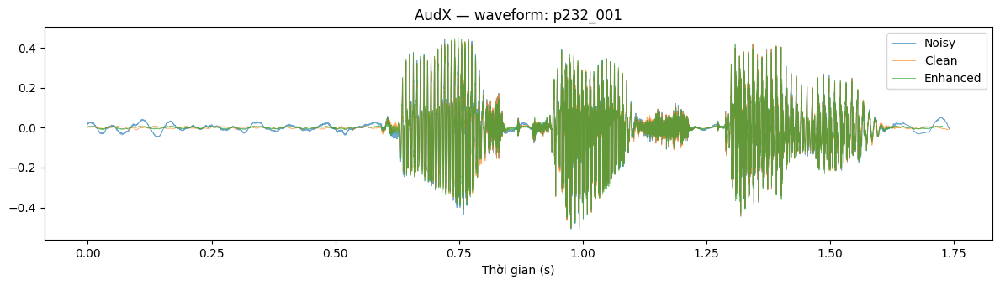

In [15]:
import matplotlib.pyplot as plt
from IPython.display import display, Audio

uid = test_ids[0]
noisy = load_audio(str(DATA_DIR/'noisy_testset_wav'/f'{uid}.wav'))
clean = load_audio(str(DATA_DIR/'clean_testset_wav'/f'{uid}.wav'))
enhanced = enhance_waveform(noisy)

for name, audio in [('sample_noisy.wav', noisy),
                    ('sample_clean.wav', clean),
                    ('sample_enhanced.wav', enhanced)]:
    sf.write(str(ROOT/name), audio, 16000)
    print(name)
    display(Audio(audio, rate=16000))

plt.figure(figsize=(12, 3.5))
for audio, label in [(noisy, 'Noisy'), (clean, 'Clean'), (enhanced, 'Enhanced')]:
    plt.plot(np.arange(len(audio))/16000, audio, alpha=0.65, linewidth=0.7, label=label)
plt.title(f'AudX — waveform: {uid}')
plt.xlabel('Thời gian (s)')
plt.legend()
plt.tight_layout()
plt.show()

## 9. Upload WAV riêng để khử nhiễu (tùy chọn)

Hãy chạy cell này nếu muốn khử nhiễu file ghi âm bên ngoài bộ test. Colab sẽ hỏi chọn file; audio được đọc lại thành mono 16 kHz bằng hàm `load_audio` của repo.

In [16]:
# # Đổi thành True khi cần upload file của bạn.
# UPLOAD_MY_AUDIO = False
# if UPLOAD_MY_AUDIO:
#     from google.colab import files
#     uploaded = files.upload()
#     if not uploaded:
#         raise ValueError('Chưa chọn file WAV/audio.')
#     user_filename = next(iter(uploaded.keys()))
#     user_audio = load_audio(user_filename)
#     user_enhanced = enhance_waveform(user_audio)
#     user_output = ROOT / (Path(user_filename).stem + '_enhanced.wav')
#     sf.write(str(user_output), user_enhanced, 16000)
#     print('File đã tạo:', user_output)
#     display(Audio(user_audio, rate=16000))
#     display(Audio(user_enhanced, rate=16000))
#     files.download(str(user_output))

In [17]:
# Reload inference model (safe state_dict; chạy được không cần chạy train lại trong session)
from models.cnn_lstm import CNNLSTM
from utils.dataset import VoiceBankDataset, collate_fn
from utils.audio import load_audio, to_spectrogram, to_waveform
from torch.utils.data import DataLoader
import torch
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CNNLSTM().to(DEVICE)
load_audx_weights(CKPT)  # dùng checkpoint bạn đã train
model.eval()
print('Inference model ready:', CKPT)


Đã nạp checkpoint: /kaggle/working/AudX/audx_model_finetuned_vi.pth
Inference model ready: /kaggle/working/AudX/audx_model_finetuned_vi.pth


In [18]:
def enhance_waveform(noisy_wave):
    mag, phase = to_spectrogram(noisy_wave)
    tensor = torch.from_numpy(mag.copy()).float().unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        predicted = model(tensor).squeeze(0).cpu().numpy()
    # Dùng to_waveform của repo; giữ nguyên cách dự đoán phổ và phase.
    return to_waveform(predicted, phase).astype(np.float32)


In [19]:
from pathlib import Path
import soundfile as sf
from tqdm.auto import tqdm
from IPython.display import display, Audio, Markdown

INPUT_DIR = Path('/kaggle/input/datasets/namcht/noise-test')
OUTPUT_DIR = ROOT / 'output_audio'

# INPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

audio_extensions = {'.wav', '.flac', '.mp3'}

audio_files = sorted(
    p for p in INPUT_DIR.rglob('*')
    if p.is_file() and p.suffix.lower() in audio_extensions
)

print('Số file inference:', len(audio_files))

# Inference
for audio_path in tqdm(audio_files, desc='AudX inference'):
    relative = audio_path.relative_to(INPUT_DIR)

    output_path = (
        OUTPUT_DIR / relative.parent /
        f'{audio_path.stem}_enhanced.wav'
    )

    output_path.parent.mkdir(parents=True, exist_ok=True)

    if output_path.exists():
        continue

    try:
        enhanced = enhance_waveform(load_audio(str(audio_path)))
        sf.write(str(output_path), enhanced, 16000)

    except Exception as e:
        print(f'Lỗi xử lý {audio_path}: {e}')

print('Đã xuất WAV:', OUTPUT_DIR)


# ==========================================
# DISPLAY: Nghe audio theo từng pair
# ==========================================

display(Markdown('# Audio Comparison: Noisy vs Enhanced'))

for audio_path in audio_files:
    relative = audio_path.relative_to(INPUT_DIR)

    output_path = (
        OUTPUT_DIR / relative.parent /
        f'{audio_path.stem}_enhanced.wav'
    )

    if not output_path.exists():
        continue

    display(Markdown(f'## {audio_path.name}'))

    # Audio gốc
    noisy, noisy_sr = sf.read(str(audio_path))

    # Audio đã xử lý
    enhanced, enhanced_sr = sf.read(str(output_path))

    display(Markdown('**Original / Noisy**'))
    display(Audio(noisy.T if noisy.ndim == 2 else noisy,
                  rate=noisy_sr))

    display(Markdown('**Enhanced / Denoised**'))
    display(Audio(enhanced.T if enhanced.ndim == 2 else enhanced,
                  rate=enhanced_sr))

    display(Markdown('---'))

Số file inference: 7


AudX inference:   0%|          | 0/7 [00:00<?, ?it/s]

Đã xuất WAV: /kaggle/working/AudX/output_audio


# Audio Comparison: Noisy vs Enhanced

## banking_trouble_in.wav

**Original / Noisy**

... (22 outputs left out)

## noise_3.wav

**Original / Noisy**

**Enhanced / Denoised**

---

In [20]:
# Tạo ZIP đầu ra, hoạt động trên Colab/Kaggle/Local Jupyter.
import shutil
if OUTPUT_DIR.exists():
    print('ZIP:', shutil.make_archive(str(ROOT/'output_audio'), 'zip', str(OUTPUT_DIR)))


ZIP: /kaggle/working/AudX/output_audio.zip


## 10. Nhận dạng giọng nói bằng Whisper (tùy chọn)

`infer.py` có import `transformers.pipeline` và Whisper base, nhưng mã repo không tự chạy khi gọi qua terminal. Cell này minh họa cách dùng Whisper với file WAV đã được cải thiện; cần tải thêm trọng số Whisper và thư viện transformers. Mặc định tắt.

In [21]:
# Inference cuối chuỗi: AudX -> Vietnamese ASR (mặc định tắt vì cần model ASR).
RUN_WHISPER = False
if RUN_WHISPER:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'transformers', 'accelerate'], check=True)
    from transformers import pipeline
    asr = pipeline('automatic-speech-recognition', model='openai/whisper-small',
                   device=0 if torch.cuda.is_available() else -1)
    transcript = asr({'array': enhanced.astype(np.float32), 'sampling_rate': 16000},
                     generate_kwargs={'language': 'vietnamese', 'task': 'transcribe'})['text']
    print('Whisper VI:', transcript)


## 11. Tải model và WAV về máy / lưu Drive

`audx_model.pth` được lưu tại `./AudX/audx_model.pth`. Nếu cần giữ sau khi Colab ngắt kết nối, bật `SAVE_TO_DRIVE=True` ở phần cấu hình và chạy lại phần train (hoặc dùng cell copy dưới đây). Bạn có thể tải file ngay bằng `files.download`.

In [22]:
# Tùy chọn tải checkpoint và WAV từ Google Colab.
DOWNLOAD_FILES = False
if DOWNLOAD_FILES:
    from google.colab import files
    files.download(str(CKPT))
    files.download(str(ROOT/'sample_enhanced.wav'))
    files.download(str(ROOT/'audx_test_metrics_colab.txt'))


## 12. Chạy đúng script `evaluate_all.py` của README (không bắt buộc)

Notebook đã chạy evaluation tại bước 7 (có thêm so sánh noisy/enhanced). Nếu muốn kiểm tra **nguyên script** `python evaluate_all.py`, bật công tắc này. Script repo tạo `audx_test_metrics.txt` và chỉ tổng hợp metrics của enhanced.

> Cảnh báo: `python train.py` nguyên bản sẽ train **30 epoch** và ghi đè checkpoint `audx_model.pth` sau khi kết thúc; notebook dùng vòng train có cấu hình để tránh bắt buộc chạy dài trong demo.

In [23]:
RUN_ORIGINAL_EVAL = False
# if RUN_ORIGINAL_EVAL:
#     subprocess.run([sys.executable, 'evaluate_all.py'], cwd=ROOT, check=True)
#     print((ROOT/'audx_test_metrics.txt').read_text())


if RUN_ORIGINAL_EVAL:
    subprocess.run(
        [sys.executable, '/kaggle/working/AudX/evaluate_all.py'],
        cwd=ROOT,
        check=True
    )
    print((ROOT / 'audx_test_metrics.txt').read_text())

### Nguồn dữ liệu và giấy phép (kiểm tra trước khi xuất bản/sử dụng thương mại)

**Dữ liệu cặp tiếng Anh:** [VoiceBank-DEMAND-16k](https://huggingface.co/datasets/JacobLinCool/VoiceBank-DEMAND-16k) (11.572 train/824 test, CC-BY-4.0).

**Clean tiếng Việt:** [VIVOS (bản AILAB)](https://huggingface.co/datasets/AILAB-VNUHCM/vivos) / [VIVOS Parquet mirror](https://huggingface.co/datasets/duymanh1606/vietnamese_asr) (~15h; CC-BY-NC-SA-4.0), [FLEURS Vietnamese](https://huggingface.co/datasets/google/fleurs) (~10h training; CC-BY-4.0), [Common Voice tiếng Việt](https://commonvoice.mozilla.org/vi) (CC0), [viVoice](https://huggingface.co/datasets/capleaf/viVoice) (~1017h, gated + phi thương mại).

**Noise:** [MUSAN](https://www.openslr.org/17/) (ambient/music/speech, CC BY 4.0 tổng thể; phải kiểm tra giấy phép từng clip), [DEMAND original](https://zenodo.org/records/1227121) / [DEMAND 16k mirror](https://huggingface.co/datasets/philgzl/demand) (gốc CC BY-SA 3.0, mirror tự ghi CC BY 4.0 → xác minh quyền tái sử dụng), [ESC-50](https://github.com/karolpiczak/ESC-50) (50 classes, CC BY-NC 3.0), [DNS Challenge](https://github.com/microsoft/DNS-Challenge) (nhiễu thực rất đa dạng; dữ liệu lớn), [WHAM noise](https://wham.whisper.ai/) (CC BY-NC 4.0), [FSD50K](https://zenodo.org/records/4060432) (giấy phép theo từng clip), [RIRs/noises OpenSLR 28](https://www.openslr.org/28/) (Apache-2.0), [speechio/asr-noises](https://github.com/speechio/asr-noises) (~20k mẫu/200 loại; kiểm tra license từng file).

**Vietnamese paired/đánh giá:** [DPDFNet EvalSet](https://huggingface.co/datasets/Ceva-IP/DPDFNet_EvalSet) (VI có clean/noisy, giữ làm benchmark), [VietENT-Speech](https://huggingface.co/datasets/diepduclai/VietENT-Speech) (TTS raw/aug có biến đổi tốc độ nói → **không train MSE framewise nếu chưa alignment**), [ViSpeech](https://github.com/TranNguyenNB/ViSpeech) (clean/noisy test không bảo đảm song song), [VN-SpeechMix](https://huggingface.co/datasets/pervasiveaidataresearchlab2025/VN-SpeechMix_Dataset) (tiếng nói chồng lấn, chỉ công bố script/metadata; cần nguồn ViMD hợp pháp), [ViSQA](https://figshare.com/articles/dataset/ViSQA_v1_0_0/29493149) (synthetic clean/noisy ASR, chủ yếu benchmark).

**Lưu ý kỹ thuật:** Nhiễu tiếng Việt thường có ý nghĩa nhất ở *speech interference* (đám đông, quán cà phê, giọng khác), tiếng xe máy/còi xe, loa phát thanh, karaoke/nhạc, công trường, mưa/quạt, nhiễu mic/điện thoại. Các nguồn global như DNS/MUSAN/ESC50 giúp đa dạng tiếng động nhưng cần bổ sung bản ghi noise-only thu ở Việt Nam để giảm domain gap. Ưu tiên kiểm tra CER/WER trên audio thực, không chỉ STOI/SDR của dữ liệu synthetic.
